# 04 · LangGraph, CrewAI, multi-agents et A2A

**Atelier Agents IA · Notebook 4 sur 4**

| | |
|---|---|
| ⏱️ Durée conseillée | 40 minutes |
| 🎓 Séquence du cours | Séquences 6 (Frameworks) et 7 (Architectures) |
| 🧰 Prérequis | Fichier `.env` rempli (voir le README) |

### Ce que vous saurez faire à la fin
- réécrire l'agent de prospection en workflow LangGraph, avec pause pour validation humaine ;
- dessiner la boucle agentique sous forme de graphe LangGraph ;
- construire une équipe d'agents avec CrewAI ;
- organiser plusieurs agents avec un superviseur ;
- comprendre ce qu'est A2A et quand l'utiliser.

> **Comment utiliser ce notebook :** exécutez les cellules **une par une, dans l'ordre**, avec `Maj + Entrée`.
> Lisez le texte avant chaque cellule de code : il explique ce qui va se passer.
> Les cellules marquées ✍️ **À vous** sont des exercices ; la solution est cachée juste en dessous (cliquez sur « Voir la solution »).

> **Un framework ne fait rien de magique.** Sous le capot, c'est la boucle du notebook 02. Il vous évite d'écrire à la main l'état, la reprise après une pause, l'enchaînement de plusieurs agents.

## 0. Configuration

In [1]:
import json
from prospection import *

verifier_configuration()

ANTHROPIC_API_KEY : ✅ présente (sk-ant…)
APIFY_TOKEN       : ✅ présente (apify_…) 
Modèle principal  : claude-sonnet-5-5
Modèle rapide     : claude-haiku-5-5


## 1. LangGraph : l'application comme un graphe

LangGraph (de l'équipe LangChain) décrit une application comme un **graphe** :

| Concept | Rôle | Dans notre code du notebook 02 |
|---|---|---|
| **State** (état) | Un dictionnaire partagé entre les étapes | Nos variables |
| **Node** (nœud) | Une fonction qui lit l'état et renvoie une mise à jour | Extraire, chercher, rédiger |
| **Edge** (arête) | Le passage d'un nœud au suivant | L'ordre des appels |
| **Conditional edge** | Une fonction qui choisit le nœud suivant | Le `if` |
| **Checkpointer** | Sauvegarde l'état à chaque étape | Rien : à coder à la main |
| **interrupt** | Met le graphe en pause en attendant un humain | Le `input()` |

### 1.1 Notre prospection en workflow

```
START → extraire → rechercher → rediger → valider (pause) ─ oui → envoyer → END
                                                         └─ non ─────────→ END
```

In [2]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.types import interrupt, Command
try:
    from langgraph.checkpoint.memory import InMemorySaver
except ImportError:                                   # anciennes versions
    from langgraph.checkpoint.memory import MemorySaver as InMemorySaver

class Etat(TypedDict, total=False):
    demande: str
    parametres: dict
    commerces: list
    messages_approche: list
    valide: bool

c:\Users\Ultra Tech\anaconda3\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (1.26.20) or chardet (7.4.3)/charset_normalizer (3.4.7) doesn't match a supported version!
  warnings.warn(
c:\Users\Ultra Tech\anaconda3\Lib\site-packages\langgraph\cache\base\__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


Chaque **nœud** est une fonction ordinaire : elle reçoit l'état et renvoie **seulement ce qu'elle modifie**.

In [3]:
def extraire(etat):
    p = extraire_parametres(etat["demande"])
    print(f"1️⃣ extraire  → {p.activite} / {p.zone} / {p.nombre}")
    return {"parametres": p.model_dump()}

def rechercher(etat):
    p = etat["parametres"]
    commerces = chercher_commerces(p["activite"], p["zone"], p["nombre"])
    print(f"2️⃣ rechercher → {len(commerces)} commerces")
    return {"commerces": commerces}

def rediger(etat):
    activite = etat["parametres"]["activite"]
    messages = [rediger_message(c["nom"], activite) for c in etat["commerces"]]
    print(f"3️⃣ rediger   → {len(messages)} messages")
    return {"messages_approche": messages}

def valider(etat):
    # Le graphe se met en PAUSE ici et rend la main au programme
    reponse = interrupt({"a_valider": etat["messages_approche"]})
    return {"valide": reponse == "oui"}

def envoyer(etat):
    for m in etat["messages_approche"]:
        print(f"📤 (simulation) envoyé à {m['commerce']}")
    return {}

def apres_validation(etat):
    return "envoyer" if etat.get("valide") else END

On assemble le graphe : les nœuds, puis les arêtes.

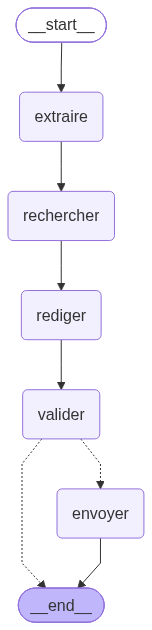

In [4]:
graphe = StateGraph(Etat)
for fonction in [extraire, rechercher, rediger, valider, envoyer]:
    graphe.add_node(fonction.__name__, fonction)

graphe.add_edge(START, "extraire")
graphe.add_edge("extraire", "rechercher")
graphe.add_edge("rechercher", "rediger")
graphe.add_edge("rediger", "valider")
graphe.add_conditional_edges("valider", apres_validation, ["envoyer", END])
graphe.add_edge("envoyer", END)

app = graphe.compile(checkpointer=InMemorySaver())   # le checkpointer permet la pause

# Afficher le graphe (si l'affichage échoue, ce n'est pas grave)
try:
    from IPython.display import Image, display
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception:
    print(app.get_graph().draw_mermaid())

### 1.2 Lancer, s'arrêter, reprendre
Le `thread_id` identifie **une exécution**. Grâce au checkpointer, on peut reprendre plus tard, même demain matin, exactement là où le graphe s'était arrêté.

In [5]:
config = {"configurable": {"thread_id": "prospection-1"}}

etat = app.invoke({"demande": "Trouve 3 boulangeries à Dakar Plateau"}, config)

print("\n⏸️ Le graphe est en pause. Messages à valider :")
for m in app.get_state(config).values["messages_approche"]:
    print(f"\n— {m['commerce']}\n{m['message']}")

1️⃣ extraire  → boulangerie / Dakar Plateau / 3
2️⃣ rechercher → 3 commerces
3️⃣ rediger   → 3 messages

⏸️ Le graphe est en pause. Messages à valider :

— Praline
Bonjour, c'est [Votre nom] de CaissePro. Nous proposons un logiciel de caisse et de gestion de stock simple, utilisable sur téléphone, compatible Wave et Orange Money, qui pourrait vous aider au quotidien chez Praline. Seriez-vous intéressé(e) pour en savoir plus ?

— LA BAGUETTE MAGIQUE, 13, RUE ROBERT BRUN PLATEAU DAKAR-PLATEAU, DAKAR SENEGAL
Bonjour, l'équipe de La Baguette Magique ! Je suis commercial chez CaissePro, un logiciel de caisse et de gestion de stock simple, utilisable directement sur téléphone et compatible avec Wave et Orange Money. Seriez-vous intéressés par un petit échange pour voir si cela peut vous aider au quotidien ?

— Boulangerie Principale
Bonjour, c'est [Votre nom] de CaissePro. Notre logiciel de caisse et de gestion de stock, simple à utiliser sur téléphone, accepte aussi les paiements Wave et Or

In [6]:
decision = input("\nValider l'envoi ? (oui/non) ").strip().lower()
etat_final = app.invoke(Command(resume=decision), config)    # reprise
print("Envoi validé :", etat_final.get("valide"))

📤 (simulation) envoyé à Praline
📤 (simulation) envoyé à LA BAGUETTE MAGIQUE, 13, RUE ROBERT BRUN PLATEAU DAKAR-PLATEAU, DAKAR SENEGAL
📤 (simulation) envoyé à Boulangerie Principale
Envoi validé : True


🤔 **Ce graphe est-il un workflow ou un agent ?**
<details><summary>Réponse</summary>Un <b>workflow</b> : l'ordre des étapes est fixé par le développeur. Pour de la prospection, c'est souvent le meilleur choix : plus fiable, moins cher, facile à auditer.</details>

### 1.3 La boucle agentique, dessinée en graphe
LangGraph sait aussi faire un vrai **agent** : un nœud « modèle », un nœud « outils », et une arête conditionnelle qui boucle. C'est **exactement** la boucle du notebook 02.

```
START → modele ─ veut un outil ? ─ oui → outils ─┐
          ▲                     └─ non → END      │
          └───────────────────────────────────────┘
```

In [7]:
import operator
from typing import Annotated

class EtatAgent(TypedDict):
    messages: Annotated[list, operator.add]     # operator.add : on AJOUTE à la liste

def noeud_modele(etat):
    rep = client.messages.create(model=MODELE, max_tokens=2000, system=SYSTEME_AGENT,
                                 tools=TOOLS, messages=etat["messages"])
    contenu = [b.model_dump(exclude_none=True) for b in rep.content]
    return {"messages": [{"role": "assistant", "content": contenu}]}

def noeud_outils(etat):
    resultats = []
    for bloc in etat["messages"][-1]["content"]:
        if bloc["type"] == "tool_use":
            print(f"🔧 {bloc['name']}({bloc['input']})")
            try:
                sortie = FONCTIONS[bloc["name"]](**bloc["input"])
            except Exception as e:
                sortie = {"erreur": str(e)}
            resultats.append({"type": "tool_result", "tool_use_id": bloc["id"],
                              "content": json.dumps(sortie, ensure_ascii=False)})
    return {"messages": [{"role": "user", "content": resultats}]}

def veut_un_outil(etat):
    dernier = etat["messages"][-1]["content"]
    return "outils" if any(b["type"] == "tool_use" for b in dernier) else END

g = StateGraph(EtatAgent)
g.add_node("modele", noeud_modele)
g.add_node("outils", noeud_outils)
g.add_edge(START, "modele")
g.add_conditional_edges("modele", veut_un_outil, ["outils", END])
g.add_edge("outils", "modele")
agent_graphe = g.compile()

fin = agent_graphe.invoke(
    {"messages": [{"role": "user", "content": "Trouve 2 pharmacies aux Almadies et rédige un message pour chacune."}]},
    {"recursion_limit": 16},          # l'équivalent de notre max_tours
)
print("".join(b.get("text", "") for b in fin["messages"][-1]["content"]))

🔧 rechercher_commerces({'activite': 'pharmacie', 'zone': 'Almadies', 'nombre': 2})
🔧 rediger_message({'nom_commerce': 'Pharmacie Rond-Point Philippe Maguilene Senghor', 'activite': 'pharmacie'})
🔧 rediger_message({'nom_commerce': "Pharmacie de l'univers", 'activite': 'pharmacie'})
Voici les 2 pharmacies trouvées aux Almadies, avec un message pour chacune.

**1. Pharmacie Rond-Point Philippe Maguilene Senghor**
Téléphone : +221 33 860 24 60. Note : 4,1/5 (43 avis).

Message proposé :
> Bonjour Monsieur Maguilene Senghor, j'espère que vous allez bien. Je me permets de vous présenter CaissePro, un logiciel de caisse et de gestion de stock simple, utilisable directement sur téléphone et compatible avec Wave et Orange Money. Seriez-vous disponible pour un petit échange de cinq minutes cette semaine ?

⚠️ Le message appelle le destinataire « Monsieur Maguilene Senghor ». Ce nom vient de l'adresse du rond-point, pas d'une personne. Je vous conseille de remplacer cette formule par « Bonjour » 

## 2. CrewAI : l'agent comme une équipe

CrewAI part d'une autre image : une **équipe de spécialistes**. On n'écrit pas un graphe, on écrit des **fiches de poste**.

| Concept | Rôle |
|---|---|
| **Agent** | Un membre de l'équipe : `role`, `goal`, `backstory` et ses outils |
| **Task** | Une mission : `description`, `expected_output`, l'agent responsable |
| **Crew** | L'équipe : les agents et les tâches |
| **Process** | `sequential` (l'un après l'autre) ou `hierarchical` (un manager délègue) |

In [10]:
from crewai import Agent, Task, Crew, Process, LLM
from crewai.tools import tool

llm = LLM(model=f"anthropic/{MODELE}")

@tool("rechercher_commerces")
def outil_recherche(activite: str, zone: str, nombre: int = 5) -> str:
    """Recherche des commerces sur Google Maps au Sénégal par activité et zone (ex. boulangerie, Dakar Plateau)."""
    return json.dumps(chercher_commerces(activite, zone, nombre), ensure_ascii=False)

chercheur = Agent(
    role="Chargé de recherche commerciale",
    goal="Trouver des commerces qui correspondent exactement à la cible demandée",
    backstory="Tu connais très bien le tissu commercial de Dakar et des régions.",
    tools=[outil_recherche], llm=llm, verbose=True,
)
redacteur = Agent(
    role="Rédacteur commercial",
    goal="Écrire des messages WhatsApp d'approche courts, polis et personnalisés",
    backstory=f"Tu rédiges des messages professionnels en français pour présenter : {OFFRE}.",
    llm=llm, verbose=True,
)

In [11]:
recherche = Task(
    description="Trouve {nombre} commerces de type {activite} à {zone}.",
    expected_output="Une liste : nom, adresse et téléphone de chaque commerce.",
    agent=chercheur,
)
redaction = Task(
    description="Rédige un message d'approche pour chaque commerce trouvé.",
    expected_output="Pour chaque commerce : son nom puis un message de 3 phrases maximum.",
    agent=redacteur,
    context=[recherche],          # le rédacteur reçoit le travail du chercheur
)

equipe = Crew(agents=[chercheur, redacteur], tasks=[recherche, redaction],
              process=Process.sequential, verbose=True)

# Jupyter tourne déjà dans une boucle asynchrone : on utilise la version async avec await.
resultat = await equipe.kickoff_async(inputs={"activite": "boulangerie", "zone": "Dakar Plateau", "nombre": 3})
print("\n" + "=" * 60 + "\nRÉSULTAT FINAL\n" + "=" * 60)
print(resultat.raw)

╭─────────────────────────────────────────── 🚀 Crew Execution Started ───────────────────────────────────────────╮
│                                                                                                                 │
│  Crew Execution Started                                                                                         │
│  Name: crew                                                                                                     │
│  ID: 1491b9e4-2ed5-43c8-8f54-ab8b1966ca25                                                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────────── 📋 Task Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Task Started                                                                                                   │
│  Name: Trouve 3 commerces de type boulangerie à Dakar Plateau.                                                  │
│  ID: 91811487-47cf-40a6-a453-01f6fe9e94cf                                                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Chargé de recherche commerciale                                                                         │
│                                                                                                                 │
│  Task: Trouve 3 commerces de type boulangerie à Dakar Plateau.                                                  │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────── 🔧 Tool Execution Started (#1) ─────────────────────────────────────────╮
│                                                                                                                 │
│  Tool: rechercher_commerces                                                                                     │
│  Args: {'activite': 'boulangerie', 'zone': 'Dakar Plateau', 'nombre': 3}                                        │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────── ✅ Tool Execution Completed (#1) ────────────────────────────────────────╮
│                                                                                                                 │
│  Tool Completed                                                                                                 │
│  Tool: rechercher_commerces                                                                                     │
│  Output: [{"nom": "Praline", "categorie": "Pâtisserie", "adresse": "14-18, Boulevard El Hadji Djily Mbaye,      │
│  Dakar 99000, Sénégal", "telephone": "+221 33 864 66 74", "site_web": null, "note": 4.5, "nb_avis": 69,         │
│  "lien_maps":                                                                                                   │
│  "https://www.google.com/maps/search/?api=1&query=Praline&query_place_id=ChIJqXvNI5ZzwQ4RNC4N26tfSGo",          │
│  "source": "Google Maps via Apify"}, {"nom": "LA BAGUETTE MAGIQUE, 13, RUE ROBERT BRUN PLATEAU DAKAR-PLATEAU,   │
│  DAKAR SENEGAL", "categorie": "Boulangerie", "adresse": "22 Rue Robert Brun, Sénégal", "telephone": "+221 70    │
│  313 68 31", "site_web": null, "note": 4, "nb_avis": 2, "lien_maps":                                            │
│  "https://www.google.com/maps/search/?api=1&query=LA%20BAGUETTE%20MAGIQUE%2C%2013%2C%20RUE%20ROBERT%20BRUN%20P  │
│  LATEAU%20DAKAR-PLATEAU%2C%20DAKAR%20SENEGAL&query_place_id=ChIJ22ndw6VzwQ4Rel4W9O4wWuU", "source": "Google     │
│  Maps via Apify"}, {"nom": "Boulangerie Principale", "categorie": "Boulangerie", "adresse": "Dakar, Sénégal",   │
│  "telephone": "", "site_web": null, "note": null, "nb_avis": null, "lien_maps":                                 │
│  "https://www.google.com/maps/search/?api=1&query=Boulangerie%20Principale&query_place_id=ChIJydDfhVFywQ4RFpqU  │
│  9KmXAhI", "source": "Google Maps via Apify"}]                                                                  │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

...

[Finalize] todos_count=0, todos_with_results=0


╭───────────────────────────────────────────── ✅ Agent Final Answer ─────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Rédacteur commercial                                                                                    │
│                                                                                                                 │
│  Final Answer:                                                                                                  │
│  **Aux Fins Palais**                                                                                            │
│  Bonjour, je vous contacte au sujet de CaissePro, un logiciel de caisse et de gestion de stock simple,          │
│  utilisable directement sur téléphone. Il permet de suivre vos ventes et vos stocks de pain et de pâtisseries,  │
│  et il accepte les paiements Wave et Orange Money. Seriez-vous d'accord pour que je vous le présente en         │
│  quelques minutes ?                                                                                             │
│                                                                                                                 │
│  **Artisan Boulanger Eric Kayser**                                                                              │
│  Bonjour, je vous écris pour vous présenter CaissePro, un logiciel de caisse et de gestion de stock simple,     │
│  utilisable sur téléphone. Il est compatible avec Wave et Orange Money, ce qui facilite l'encaissement et le    │
│  suivi de vos stocks en boutique. Puis-je vous en faire une courte démonstration, ou vous envoyer plus          │
│  d'informations ici ?                                                                                           │
│                                                                                                                 │
│  **La Baguette Magique**                                                                                        │
│  Bonjour, je me permets de vous contacter pour vous faire découvrir CaissePro, un logiciel de caisse et de      │
│  gestion de stock simple, qui s'utilise sur téléphone. Il est compatible avec Wave et Orange Money, pour        │
│  encaisser facilement et savoir ce qu'il vous reste en stock. Auriez-vous quelques minutes pour que je vous le  │
│  présente ?                                                                                                     │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭────────────────────────────────────────────── 📋 Task Completion ───────────────────────────────────────────────╮
│                                                                                                                 │
│  Task Completed                                                                                                 │
│  Name: Rédige un message d'approche pour chaque commerce trouvé.                                                │
│  Agent: Rédacteur commercial                                                                                    │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────────── Crew Completion ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Crew Execution Completed                                                                                       │
│  Name: crew                                                                                                     │
│  ID: 1491b9e4-2ed5-43c8-8f54-ab8b1966ca25                                                                       │
│  Final Output: **Aux Fins Palais**                                                                              │
│  Bonjour, je vous contacte au sujet de CaissePro, un logiciel de caisse et de gestion de stock simple,          │
│  utilisable directement sur téléphone. Il permet de suivre vos ventes et vos stocks de pain et de pâtisseries,  │
│  et il accepte les paiements Wave et Orange Money. Seriez-vous d'accord pour que je vous le présente en         │
│  quelques minutes ?                                                                                             │
│                                                                                                                 │
│  **Artisan Boulanger Eric Kayser**                                                                              │
│  Bonjour, je vous écris pour vous présenter CaissePro, un logiciel de caisse et de gestion de stock simple,     │
│  utilisable sur téléphone. Il est compatible avec Wave et Orange Money, ce qui facilite l'encaissement et le    │
│  suivi de vos stocks en boutique. Puis-je vous en faire une courte démonstration, ou vous envoyer plus          │
│  d'informations ici ?                                                                                           │
│                                                                                                                 │
│  **La Baguette Magique**                                                                                        │
│  Bonjour, je me permets de vous contacter pour vous faire découvrir CaissePro, un logiciel de caisse et de      │
│  gestion de stock simple, qui s'utilise sur téléphone. Il est compatible avec Wave et Orange Money, pour        │
│  encaisser facilement et savoir ce qu'il vous reste en stock. Auriez-vous quelques minutes pour que je vous le  │
│  présente ?                                                                                                     │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯


RÉSULTAT FINAL
**Aux Fins Palais**
Bonjour, je vous contacte au sujet de CaissePro, un logiciel de caisse et de gestion de stock simple, utilisable directement sur téléphone. Il permet de suivre vos ventes et vos stocks de pain et de pâtisseries, et il accepte les paiements Wave et Orange Money. Seriez-vous d'accord pour que je vous le présente en quelques minutes ?

**Artisan Boulanger Eric Kayser**
Bonjour, je vous écris pour vous présenter CaissePro, un logiciel de caisse et de gestion de stock simple, utilisable sur téléphone. Il est compatible avec Wave et Orange Money, ce qui facilite l'encaissement et le suivi de vos stocks en boutique. Puis-je vous en faire une courte démonstration, ou vous envoyer plus d'informations ici ?

**La Baguette Magique**
Bonjour, je me permets de vous contacter pour vous faire découvrir CaissePro, un logiciel de caisse et de gestion de stock simple, qui s'utilise sur téléphone. Il est compatible avec Wave et Orange Money, pour encaisser facilement e

💬 **Remarquez :** le code CrewAI se lit presque comme une description de poste, mais **une partie du comportement est cachée** (c'est le framework qui écrit les prompts). D'où l'importance de `verbose=True`.

✍️ **À vous :** ajoutez `human_input=True` à la tâche `redaction` et relancez : CrewAI vous demandera votre avis avant de finaliser.

### 2.1 Comparer et choisir

| Critère | Boucle à la main | LangGraph | CrewAI |
|---|---|---|---|
| Image mentale | Une boucle | Un graphe d'états | Une équipe avec des rôles |
| Contrôle du flux | Total | Total et explicite | Partiel, implicite |
| Pause et reprise | À coder | Intégrées | Limitées |
| Prise en main | Rapide | Plus lente | Très rapide |
| Coût en appels | Minimal | Minimal | Plus élevé |
| Idéal pour | Apprendre, petits agents | Production, flux longs ou critiques | Prototypes, tâches en rôles |

## 3. Multi-agents : un superviseur et ses spécialistes

Un système **multi-agents**, c'est plusieurs agents spécialisés qui coopèrent. Trois organisations :

| Organisation | Principe | Quand |
|---|---|---|
| **Superviseur** | Un chef délègue aux spécialistes et rassemble le travail | Le plus courant, le plus contrôlable |
| **Réseau** | Les agents se parlent directement | Rare : difficile à prévoir et déboguer |
| **Transfert** (handoff) | Un agent passe la main à un autre, avec le contexte | Service client : accueil → ventes ou support |

L'astuce pour construire un superviseur : **chaque sous-agent devient un outil du superviseur.**

In [12]:
def agent_recherche(consigne: str) -> str:
    """Sous-agent spécialiste : il n'a QUE l'outil de recherche."""
    return agent(consigne, outils=[OUTIL_RECHERCHE],
                 fonctions={"rechercher_commerces": chercher_commerces},
                 systeme="Tu es un spécialiste de la recherche de commerces. Renvoie une liste claire.",
                 bavard=False)

def agent_redaction(consigne: str) -> str:
    """Sous-agent spécialiste : il n'a QUE l'outil de rédaction."""
    return agent(consigne, outils=[OUTIL_REDACTION],
                 fonctions={"rediger_message": rediger_message},
                 systeme="Tu es un spécialiste de la rédaction commerciale.",
                 bavard=False)

def outil_delegation(nom, description):
    return {"name": nom, "description": description,
            "input_schema": {"type": "object",
                             "properties": {"consigne": {"type": "string",
                                                         "description": "Consigne complète et autonome pour le spécialiste"}},
                             "required": ["consigne"]}}

OUTILS_SUPERVISEUR = [
    outil_delegation("deleguer_recherche", "Confie une recherche de commerces au spécialiste recherche."),
    outil_delegation("deleguer_redaction", "Confie la rédaction de messages au spécialiste rédaction. "
                                           "Donne-lui les noms des commerces."),
]
FONCTIONS_SUPERVISEUR = {"deleguer_recherche": agent_recherche,
                         "deleguer_redaction": agent_redaction}

print(agent("Trouve 2 boulangeries à Dakar Plateau et prépare un message pour chacune.",
            outils=OUTILS_SUPERVISEUR, fonctions=FONCTIONS_SUPERVISEUR,
            systeme="Tu es un superviseur. Tu ne fais rien toi-même : tu délègues aux spécialistes "
                    "puis tu présentes le résultat final."))

🔧 Tour 1 : deleguer_recherche({"consigne": "Trouve 2 boulangeries situées à Dakar Plateau (Sénégal). Pour chacune, donne le nom exact, l'adresse, et si possible le téléphone et les spécialités."})
🔧 Tour 2 : deleguer_redaction({"consigne": "Rédige un court message professionnel et cordial en français pour chacune de ces deux commerces de Dakar Plateau : 1) Praline (pâtisserie/boulangerie, Boulevard El Hadji Djily Mbaye) ; 2) La Baguette Magique (Rue Robert Brun). Les messages sont une prise de contact (demande d'informations sur les produits, horaires et possibilité de commande). N'invente aucune spécialité. Laisse un champ [Nom de l'expéditeur] à compléter. Présente deux messages distincts, clairement intitulés par le nom du commerce."})
✅ Terminé en 3 tour(s) · 4659 tokens en entrée, 1310 en sortie ≈ 20.2 FCFA
Voici les deux boulangeries trouvées à Dakar Plateau, avec un message pour chacune.

## Les commerces

**1. Praline**
- Adresse : 14-18, Boulevard El Hadji Djily Mbaye
- Téléph

⚠️ **Plus d'agents ne veut pas dire meilleur résultat.** Chaque agent ajoute des appels (coût, lenteur) et chaque passage de relais peut perdre de l'information. Comparez la consommation avec l'agent unique du notebook 02 :

In [13]:
print("Consommation de la session :", COMPTEUR)

Consommation de la session : 10727 tokens en entrée, 4120 en sortie ≈ 56.4 FCFA


> **Règle de décision :** un appel suffit-il ? Sinon un workflow ? Sinon un agent unique ? Le multi-agents vient **seulement** quand un agent a trop d'outils ou des consignes contradictoires.

**En CrewAI**, le superviseur s'obtient avec `Process.hierarchical` :
```python
equipe = Crew(agents=[chercheur, redacteur], tasks=[recherche, redaction],
              process=Process.hierarchical, manager_llm=llm)
```

## 4. A2A : quand les agents de deux organisations se parlent

Jusqu'ici, tous nos agents vivent dans **le même programme**. Mais si votre agent de prospection doit prendre rendez-vous avec **l'agent d'un partenaire**, écrit par une autre équipe, avec un autre framework ?

C'est le rôle d'**A2A** (*Agent2Agent*), un protocole ouvert lancé par Google en avril 2025 et aujourd'hui géré par la Linux Foundation.

| | MCP | A2A |
|---|---|---|
| Relie | un agent à ses **outils** | un agent à **un autre agent** |
| Exemple | Notre agent ↔ Google Maps | Notre agent ↔ agent de prise de RDV d'un partenaire |

Le principe en 4 étapes :
1. Chaque agent publie une **Agent Card** : une fiche d'identité JSON (compétences, adresse, authentification).
2. Un autre agent la lit et lui envoie une **tâche**.
3. Il suit l'avancement en direct (statuts envoyés en continu).
4. Il récupère à la fin un **artefact** : le résultat.

Voici à quoi ressemble une Agent Card (exemple simplifié) :

In [ ]:
agent_card = {
    "name": "Agent de prospection CaissePro",
    "description": "Trouve des commerces au Sénégal et rédige des messages d'approche.",
    "url": "https://agents.exemple.sn/prospection",
    "version": "1.0.0",
    "capabilities": {"streaming": True},
    "defaultInputModes": ["text/plain"],
    "defaultOutputModes": ["application/json"],
    "skills": [{
        "id": "trouver-prospects",
        "name": "Trouver des prospects",
        "description": "Cherche des commerces par activité et zone, avec un message pour chacun.",
        "examples": ["Trouve 5 boulangeries à Dakar Plateau"],
    }],
}
print(json.dumps(agent_card, indent=2, ensure_ascii=False))

> Le SDK Python officiel s'appelle `a2a-sdk`, et LangGraph comme CrewAI proposent des intégrations. La spécification évolue vite : consultez [a2a-protocol.org](https://a2a-protocol.org) avant de vous lancer. **Pour deux agents dans votre propre programme, un simple appel de fonction suffit** (comme notre superviseur).

## 🎯 Récapitulatif de l'atelier

| Notebook | Ce que vous avez construit |
|---|---|
| 01 | Appels au modèle, coût, JSON fiable |
| 02 | Outils, boucle agentique, Apify, RAG, MCP |
| 03 | Validation humaine, défense contre l'injection, budget, journal, évaluation |
| 04 | Workflow et agent LangGraph, équipe CrewAI, superviseur, A2A |

## 🚀 Votre mission pour la semaine prochaine
Reprenez l'agent et adaptez-le à **un vrai cas de votre travail** (service client, prise de rendez-vous, assistant interne…), dans le framework de votre choix, avec :
- au moins **une validation humaine** sur les actions sensibles ;
- au moins **trois cas de test** ;
- un **budget** maximum par exécution.